# Assignment 1 — Motor parameter identification

Name: Karimov Shoxiddin
Student ID: 240050


## 1. Data format and experiment

Files are whitespace-separated, with no header.

| Column | Meaning | Unit |
|---|---|---|
| 0 | Phase: 1 = powered step, 0 = power off, 2 = initial zero check, 3 = chirp | code |
| 1 | Test PWM level; during phase 0 it retains the previous level even though power is off | % |
| 2 | Left encoder, E4 | degrees, as stated in source notebook |
| 3 | Right encoder, E3 | degrees, as stated in source notebook |
| 4 | Time since the current segment/level began | ms |
| 5 | Logged battery voltage | V |

`steps_data.txt` and `steps_data_2.txt` contain −100% to +100% in 10% increments, including zero. Each level has about 2 seconds powered and 2 seconds power off. The assignment's example used a 1-second off interval; this analysis follows the actual 2-second recordings. Both motors were commanded in the same run. `steps_data_load.txt` contains ±50% tests described as loaded.

`chirp_wheels_lifted.txt` contains an 80% amplitude chirp from 0.1 to 5 Hz over 30 seconds. These are the supplied settings, not the earlier nine-file experiment. The battery column is sampled periodically and held between reads; it is not a separate terminal-voltage measurement at every row.

Time and encoder position reset between step levels, so taking differences across the whole file would be wrong. Only differences inside a level and phase are used.


In [42]:
import io
from IPython.display import display, Markdown

def data_path(filename):
    return 'motor_data/' + filename

import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

def load_runs(path):
    data = np.loadtxt(path)
    phase_all, power_all, encL_all, encR_all, time_all, bat_all = data.T
    runs = []
    for p in np.unique(power_all):
        m = (power_all == p) & (phase_all == 1)
        if not m.any():
            continue
        runs.append({'power': p, 'time': (time_all[m] - time_all[m][0]) / 1000, 'L': np.deg2rad(encL_all[m] - encL_all[m][0]), 'R': np.deg2rad(encR_all[m] - encR_all[m][0]), 'U': p / 100 * bat_all[m].mean()})
    return (runs, bat_all)
FILES = {'run1': data_path('steps_wheels_lifted_run1.txt'), 'run2': data_path('steps_wheels_lifted_run2.txt'), 'floor': data_path('steps_wheels_on_floor.txt')}
all_runs, all_bat = ({}, {})
for name, path in FILES.items():
    all_runs[name], all_bat[name] = load_runs(path)
    r = all_runs[name]
    print(f"{name}: {len(r)} runs, power {r[0]['power']:.0f} .. {r[-1]['power']:.0f} %, battery {all_bat[name].min():.2f} .. {all_bat[name].max():.2f} V")
runs, bat_all = (all_runs['run1'], all_bat['run1'])

run1: 21 runs, power -100 .. 100 %, battery 11.64 .. 11.67 V
run2: 21 runs, power -100 .. 100 %, battery 11.29 .. 11.33 V
floor: 2 runs, power -50 .. 50 %, battery 11.29 .. 11.30 V


In [43]:
from pathlib import Path
import pandas as pd
raw = {name: np.loadtxt(path) for name, path in FILES.items()}
raw['chirp'] = np.loadtxt(data_path('chirp_wheels_lifted.txt'))
audit_rows = []
for name, a in raw.items():
    assert a.shape[1] == 6 and np.isfinite(a).all()
    audit_rows.append([name, len(a), ', '.join((str(int(x)) for x in np.unique(a[:, 0]))), a[:, 5].min(), a[:, 5].max()])
audit = pd.DataFrame(audit_rows, columns=['file', 'rows', 'phases', 'battery_min_V', 'battery_max_V'])
print(audit.to_string(index=False))
assert all(np.all(a[:,5] > 0) for a in raw.values()), "Battery voltage missing: enter actual voltage before voltage-based analysis."

 file  rows  phases  battery_min_V  battery_max_V
 run1  1919 0, 1, 2      11.635987      11.674861
 run2  1551 0, 1, 2      11.286130      11.325004
floor   152 0, 1, 2      11.286130      11.299088
chirp   341    2, 3      11.532326      11.635987


## 2. Model and derivation

The first-order speed model is

\[
T_m\frac{d\omega}{dt}+\omega=\omega_{ss},\qquad \omega(0)=0.
\]

Here $T_m$ is the time constant in seconds, $\omega$ is angular speed in rad/s, and $\omega_{ss}$ is the final speed at a fixed input. Multiplying by the integrating factor $e^{t/T_m}$ gives

\[
\frac{d}{dt}(\omega e^{t/T_m})=\frac{\omega_{ss}}{T_m}e^{t/T_m}
\quad\Rightarrow\quad \omega=\omega_{ss}+Ce^{-t/T_m}.
\]

Starting from rest gives $C=-\omega_{ss}$. Integrating speed gives angle:

\[
\theta(t)-\theta(0)=\int_0^t\omega_{ss}(1-e^{-s/T_m})ds
=\omega_{ss}[t-T_m+T_m e^{-t/T_m}].
\]

After one time constant, speed is about 63.2% of its final value. A larger $T_m$ means slower acceleration.

The assignment uses $U\approx(\mathrm{PWM}/100)U_{battery}$ and $\omega_{ss}=U/k_e$. Thus $k_e$ has units V·s/rad. This estimates effective applied voltage; driver losses are not measured. The fitted constant is an effective model parameter, not an independently measured electrical back-EMF constant.

Assumptions: negligible inductance; approximately linear viscous effects over the fitted range; approximately constant load and battery voltage within a step. The model does not describe static friction and backlash explicitly. These data can reveal disagreement with the model, but cannot separately measure inductance or prove a particular friction law.

Each step is shifted to its first recorded time and angle. This follows the assignment but approximates the first sample as the start from rest. Motor commands and encoder reads occur sequentially, so fitted time constants can include timing bias.


In [44]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def fit_run(t, ang):
    p0 = [ang[-1] / t[-1], 0.2]
    popt, pcov = optimize.curve_fit(model, t, ang, p0=p0, bounds=([-np.inf, 0.001], [np.inf, 5]))
    err = np.sqrt(np.diag(pcov))
    return (popt, err)

## 3. Fit all step levels

I fit the angle formula to the powered rows for each motor and command. A segment with less than 1 radian net movement is not fitted. The standard errors come from the fit covariance; they describe uncertainty conditional on the model and do not include timing or calibration bias. A time constant at a fitting bound is not reliable.

For the speed/PWM line, I use |PWM| ≥ 50%, separately for forward and reverse. This is the selected high-command range, not proof that lower commands follow the same line. If the fitted slope is s rad/s per PWM point, the effective constant is `mean_battery / (100*s)`. The slope itself is not k_e. The intercept is kept as an empirical refinement when predicting speed.

The smallest tested moving command is 10%. This gives only a coarse bound on the dead zone. A threshold of 10% in the later model is a trial choice, not a measured exact threshold.


In [45]:
import os
pct = np.array([r['power'] for r in runs])
U = np.array([r['U'] for r in runs])
w_ss, T_m_run, w_err, T_m_err = ({}, {}, {}, {})
for wh in ('L', 'R'):
    w_ss[wh] = np.full(len(runs), np.nan)
    T_m_run[wh] = np.full(len(runs), np.nan)
    w_err[wh] = np.full(len(runs), np.nan)
    T_m_err[wh] = np.full(len(runs), np.nan)
    for i, r in enumerate(runs):
        if abs(r[wh][-1]) >= 1:
            (w_ss[wh][i], T_m_run[wh][i]), (w_err[wh][i], T_m_err[wh][i]) = fit_run(r['time'], r[wh])
lin = np.abs(pct) >= 50
u_bat = bat_all.mean()
params = {}
for wh in ('L', 'R'):
    for name, side in (('fwd', pct > 0), ('rev', pct < 0)):
        moved = side & ~np.isnan(w_ss[wh])
        f = moved & lin
        slope, b = np.polyfit(pct[f], w_ss[wh][f], 1)
        params[wh, name] = {'dz': np.abs(pct[moved]).min(), 'slope': slope, 'b': b, 'k_e': u_bat / (100 * slope), 'T_m': np.mean(T_m_run[wh][f]), 'T_m_std': np.std(T_m_run[wh][f], ddof=1)}
rows = ['| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |', '|---|---|---:|---:|---:|---:|---:|---:|']
for (wh, name), p in params.items():
    rows.append(f"| {wh} | {name} | < {p['dz']:.0f} | {p['slope']:.4f} | {p['b']:+.2f} | {p['k_e']:.3f} | {p['T_m']:.3f} ± {p['T_m_std']:.3f} | {u_bat:.2f} |")
f = io.StringIO()
f.write('\n'.join(rows) + '\n')
display(Markdown(f.getvalue()))
print('\n'.join(rows))

def cell(x, digits):
    return '–' if np.isnan(x) else f'{x:.{digits}f}'
f = io.StringIO()
f.write('| PWM, % | U, V | L: ω_ss, rad/s | L: T_m, s | R: ω_ss, rad/s | R: T_m, s |\n')
f.write('|---:|---:|---:|---:|---:|---:|\n')
for i in range(len(runs)):
    f.write(f"| {pct[i]:.0f} | {U[i]:.2f} | {cell(w_ss['L'][i], 2)} ± {cell(w_err['L'][i], 2)} | {cell(T_m_run['L'][i], 3)} ± {cell(T_m_err['L'][i], 3)} | {cell(w_ss['R'][i], 2)} ± {cell(w_err['R'][i], 2)} | {cell(T_m_run['R'][i], 3)} ± {cell(T_m_err['R'][i], 3)} |\n")
display(Markdown(f.getvalue()))
bound_hits = []
for wh in ('L', 'R'):
    for i, power in enumerate(pct):
        if np.isfinite(T_m_run[wh][i]) and (T_m_run[wh][i] <= 0.00101 or T_m_run[wh][i] >= 4.999):
            bound_hits.append((wh, power, T_m_run[wh][i]))
print('Time-constant bound hits:', bound_hits)
fit_rows = []
for i, power in enumerate(pct):
    for wh in ('L', 'R'):
        fit_rows.append([wh, power, w_ss[wh][i], w_err[wh][i], T_m_run[wh][i], T_m_err[wh][i]])
for wh in ('L', 'R'):
    print('Motor', wh)
    display(pd.DataFrame({'PWM_percent':pct, 'speed_rad_s':w_ss[wh], 'speed_SE':w_err[wh], 'Tm_s':T_m_run[wh], 'Tm_SE':T_m_err[wh]}))


| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |
|---|---|---:|---:|---:|---:|---:|---:|
| L | fwd | < 10 | 0.1235 | +2.92 | 0.943 | 0.099 ± 0.042 | 11.65 |
| L | rev | < 10 | 0.1077 | -3.51 | 1.081 | 0.113 ± 0.058 | 11.65 |
| R | fwd | < 10 | 0.1027 | +5.20 | 1.134 | 0.080 ± 0.037 | 11.65 |
| R | rev | < 10 | 0.1009 | -5.13 | 1.155 | 0.077 ± 0.053 | 11.65 |


| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |
|---|---|---:|---:|---:|---:|---:|---:|
| L | fwd | < 10 | 0.1235 | +2.92 | 0.943 | 0.099 ± 0.042 | 11.65 |
| L | rev | < 10 | 0.1077 | -3.51 | 1.081 | 0.113 ± 0.058 | 11.65 |
| R | fwd | < 10 | 0.1027 | +5.20 | 1.134 | 0.080 ± 0.037 | 11.65 |
| R | rev | < 10 | 0.1009 | -5.13 | 1.155 | 0.077 ± 0.053 | 11.65 |


| PWM, % | U, V | L: ω_ss, rad/s | L: T_m, s | R: ω_ss, rad/s | R: T_m, s |
|---:|---:|---:|---:|---:|---:|
| -100 | -11.66 | -14.44 ± 0.03 | 0.035 ± 0.003 | -15.29 ± 0.04 | 0.001 ± 0.003 |
| -90 | -10.48 | -13.11 ± 0.05 | 0.071 ± 0.004 | -14.09 ± 0.03 | 0.041 ± 0.003 |
| -80 | -9.31 | -12.09 ± 0.04 | 0.092 ± 0.003 | -13.29 ± 0.04 | 0.091 ± 0.003 |
| -70 | -8.15 | -10.94 ± 0.04 | 0.133 ± 0.004 | -12.16 ± 0.05 | 0.108 ± 0.005 |
| -60 | -6.99 | -9.90 ± 0.05 | 0.156 ± 0.006 | -11.12 ± 0.05 | 0.068 ± 0.005 |
| -50 | -5.82 | -9.05 ± 0.04 | 0.194 ± 0.006 | -10.23 ± 0.04 | 0.153 ± 0.005 |
| -40 | -4.65 | -8.28 ± 0.04 | 0.201 ± 0.006 | -9.49 ± 0.06 | 0.173 ± 0.007 |
| -30 | -3.49 | -6.88 ± 0.06 | 0.241 ± 0.009 | -7.98 ± 0.06 | 0.201 ± 0.009 |
| -20 | -2.33 | -5.56 ± 0.05 | 0.191 ± 0.011 | -6.59 ± 0.07 | 0.218 ± 0.012 |
| -10 | -1.16 | -3.83 ± 0.06 | 0.291 ± 0.019 | -4.91 ± 0.07 | 0.323 ± 0.017 |
| 0 | 0.00 | – ± – | – ± – | – ± – | – ± – |
| 10 | 1.16 | 4.30 ± 0.15 | 0.457 ± 0.044 | 4.92 ± 0.09 | 0.288 ± 0.021 |
| 20 | 2.33 | 5.63 ± 0.06 | 0.227 ± 0.012 | 6.72 ± 0.07 | 0.244 ± 0.011 |
| 30 | 3.49 | 7.06 ± 0.05 | 0.218 ± 0.009 | 8.18 ± 0.07 | 0.208 ± 0.011 |
| 40 | 4.66 | 8.76 ± 0.06 | 0.218 ± 0.009 | 9.62 ± 0.06 | 0.168 ± 0.007 |
| 50 | 5.82 | 9.27 ± 0.04 | 0.132 ± 0.006 | 10.43 ± 0.05 | 0.090 ± 0.005 |
| 60 | 6.98 | 10.32 ± 0.05 | 0.147 ± 0.005 | 11.25 ± 0.06 | 0.120 ± 0.006 |
| 70 | 8.16 | 11.39 ± 0.04 | 0.127 ± 0.004 | 12.38 ± 0.04 | 0.119 ± 0.004 |
| 80 | 9.31 | 12.72 ± 0.04 | 0.085 ± 0.004 | 13.42 ± 0.03 | 0.079 ± 0.003 |
| 90 | 10.47 | 13.97 ± 0.04 | 0.061 ± 0.004 | 14.45 ± 0.03 | 0.044 ± 0.003 |
| 100 | 11.64 | 15.45 ± 0.03 | 0.045 ± 0.003 | 15.50 ± 0.03 | 0.031 ± 0.002 |


Time-constant bound hits: [('R', np.float64(-100.0), np.float64(0.0010000000003917138))]
Motor L


,PWM_percent,speed_rad_s,speed_SE,Tm_s,Tm_SE
0,-100.0,-14.437297,0.034066,0.034533,0.002711
1,-90.0,-13.105711,0.045956,0.071138,0.003912
2,-80.0,-12.088667,0.037234,0.092171,0.003474
3,-70.0,-10.940877,0.039712,0.133022,0.004120
4,-60.0,-9.896107,0.048051,0.155686,0.005502
5,-50.0,-9.051721,0.044903,0.193564,0.005682
6,-40.0,-8.277460,0.044496,0.200786,0.006116
7,-30.0,-6.880753,0.055750,0.241180,0.009326
8,-20.0,-5.559024,0.052306,0.191388,0.010648
9,-10.0,-3.829473,0.061787,0.291405,0.018984


Motor R


,PWM_percent,speed_rad_s,speed_SE,Tm_s,Tm_SE
0,-100.0,-15.292915,0.037106,0.001000,0.002800
1,-90.0,-14.086670,0.032079,0.040562,0.002541
2,-80.0,-13.286214,0.039512,0.091368,0.003354
3,-70.0,-12.161152,0.049472,0.107663,0.004612
4,-60.0,-11.124555,0.053473,0.067643,0.005430
5,-50.0,-10.233705,0.042266,0.152831,0.004715
6,-40.0,-9.494652,0.059498,0.173297,0.007101
7,-30.0,-7.980326,0.063641,0.201251,0.009113
8,-20.0,-6.591480,0.070499,0.217876,0.012153
9,-10.0,-4.909550,0.069661,0.323083,0.016859


The tables above give the estimates for both motors. Variation in Tm across levels shows how well the constant-time-constant assumption works. The directional summary reports mean Tm ± standard deviation across selected levels; this spread is different from each fit's standard error.

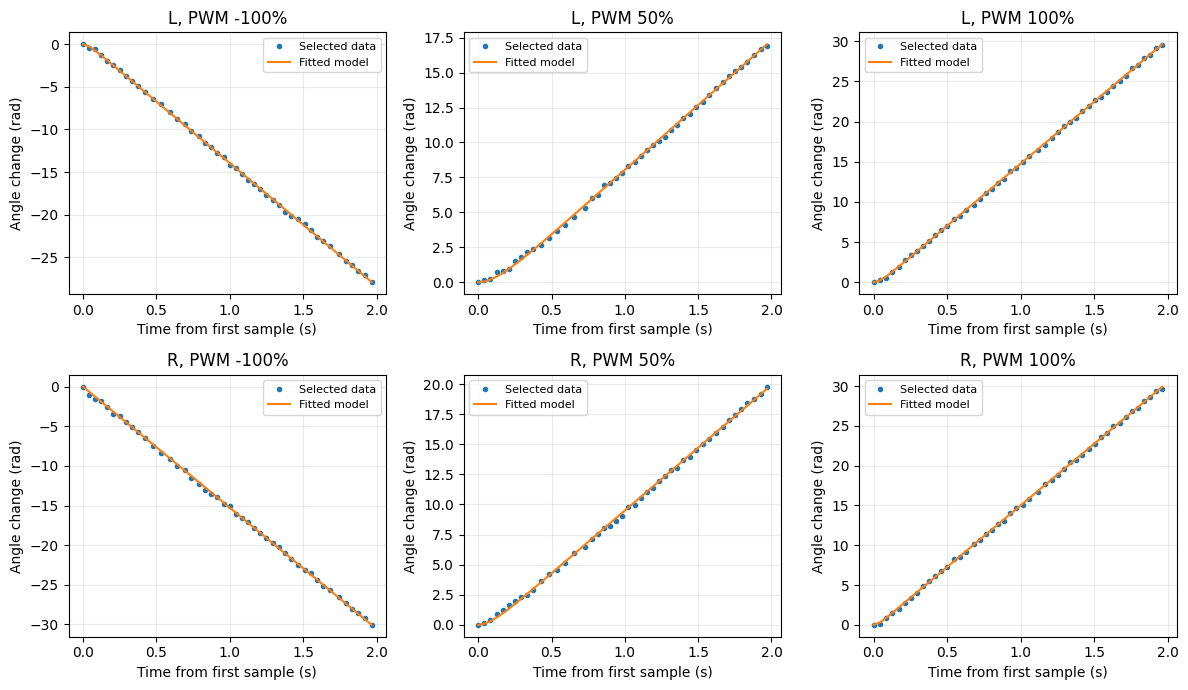

In [46]:
colors = {'L': '#2a6fdb', 'R': '#e0533d'}
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, wh in enumerate(('L', 'R')):
    for col, level in enumerate((-100, 50, 100)):
        i = list(pct).index(level)
        r = runs[i]
        ax = axes[row, col]
        ax.plot(r['time'], r[wh], '.', label='Selected data')
        ax.plot(r['time'], model(r['time'], w_ss[wh][i], T_m_run[wh][i]), label='Fitted model')
        ax.set(title=f'{wh}, PWM {level}%', xlabel='Time from first sample (s)', ylabel='Angle change (rad)')
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Step-response caption:** selected angle and fitted first-order response at three command levels for each motor. These are fitting examples, not independent validation.

wheel L fwd: slope=0.1235, intercept=2.9240, k_e=0.9432 V*s/rad
wheel L rev: slope=0.1077, intercept=-3.5072, k_e=1.0812 V*s/rad
wheel R fwd: slope=0.1027, intercept=5.1999, k_e=1.1337 V*s/rad
wheel R rev: slope=0.1009, intercept=-5.1317, k_e=1.1546 V*s/rad


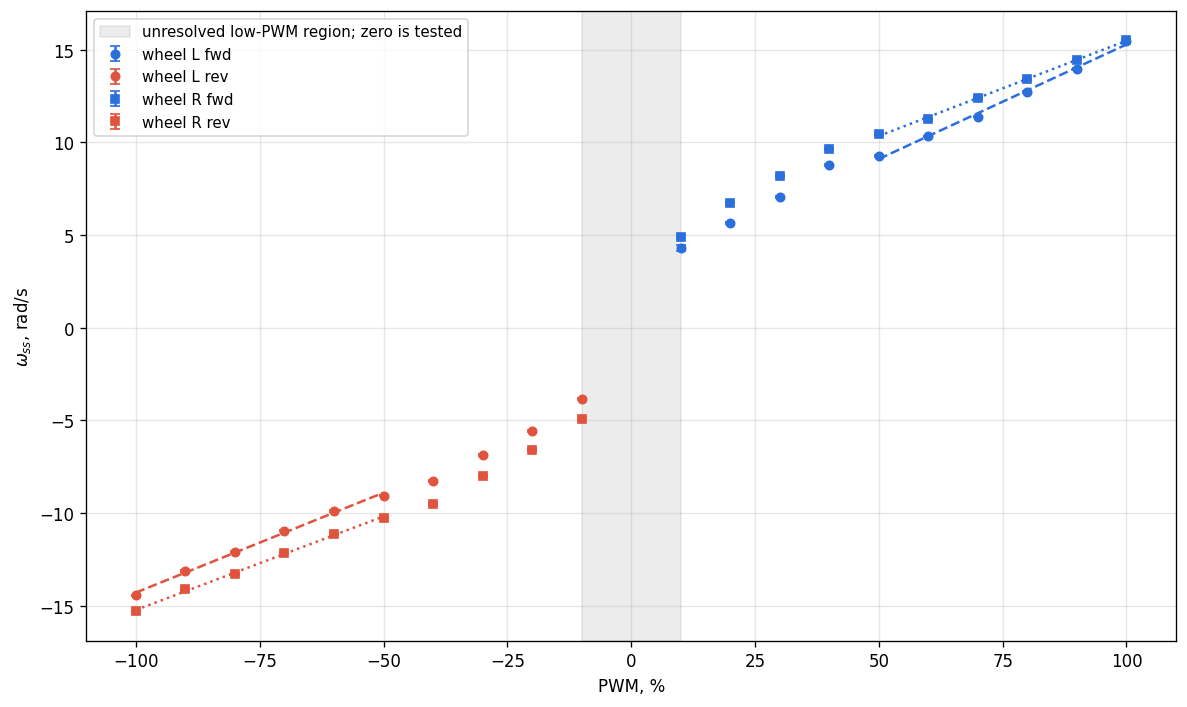

In [47]:
markers = {'L': 'o', 'R': 's'}
styles = {'L': '--', 'R': ':'}
dir_colors = {'fwd': '#2a6fdb', 'rev': '#e0533d'}
lin = np.abs(pct) >= 50
plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    for side, name in ((pct > 0, 'fwd'), (pct < 0, 'rev')):
        m = side & ~np.isnan(w_ss[wh])
        plt.errorbar(pct[m], w_ss[wh][m], yerr=w_err[wh][m], fmt=markers[wh], color=dir_colors[name], ms=5, capsize=3, label=f'wheel {wh} {name}')
        f = m & lin
        slope, icpt = np.polyfit(pct[f], w_ss[wh][f], 1)
        x_line = pct[f]
        plt.plot(x_line, slope * x_line + icpt, linestyle=styles[wh], color=dir_colors[name], lw=1.5)
        u_bat = bat_all.mean()
        k_e_calc = u_bat / (100 * slope)
        print(f'wheel {wh} {name}: slope={slope:.4f}, intercept={icpt:.4f}, k_e={k_e_calc:.4f} V*s/rad')
plt.axvspan(-10, 10, color='grey', alpha=0.15, label='unresolved low-PWM region; zero is tested')
plt.xlabel('PWM, %')
plt.ylabel('$\\omega_{ss}$, rad/s')
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Speed/PWM caption:** forward and reverse results are coloured separately; marker shapes distinguish motors. Lines are fitted only over |PWM| ≥ 50%. The grey region is not a measured dead-zone boundary. A nonzero intercept means the high-command line should not be extrapolated to rest without qualification.

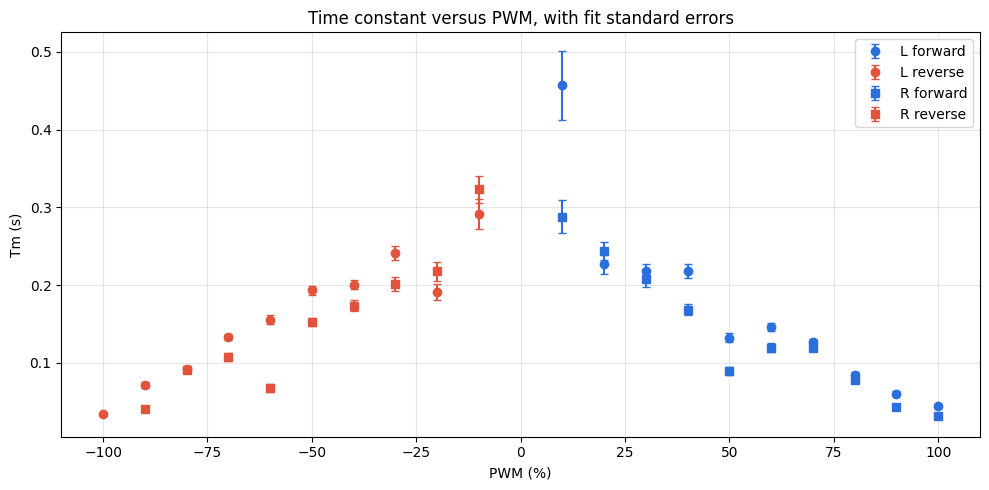

In [48]:
plt.figure(figsize=(10, 5))
for wh, marker in [('L', 'o'), ('R', 's')]:
    for direction, mask, color in [('forward', pct > 0, '#2a6fdb'), ('reverse', pct < 0, '#e0533d')]:
        good = mask & np.isfinite(T_m_run[wh]) & (T_m_run[wh] > 0.00101) & (T_m_run[wh] < 4.999)
        plt.errorbar(pct[good], T_m_run[wh][good], yerr=T_m_err[wh][good], fmt=marker, color=color, capsize=3, label=f'{wh} {direction}')
plt.xlabel('PWM (%)')
plt.ylabel('Tm (s)')
plt.title('Time constant versus PWM, with fit standard errors')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Tm/PWM caption:** these estimates include the effects of the fitting approximation and sampling. Bound-hit results are excluded. Some high-command time constants are shorter than a typical sampling interval. Those fast transients are poorly resolved even when covariance-based error bars are small. The observed variation should not automatically be attributed to a physical change in motor inertia.

## 4. Step-trained model on the chirp

The chirp is not used to fit the parameters. I use the high-command directional speed lines and mean directional Tm from the first step experiment. The target speed is `U/k_e + intercept` for nonzero input. This is an empirical extension of the assignment's ideal zero-intercept model; it may fail near zero.

The comparison uses the same parameters with and without a trial 10% dead-zone threshold. The threshold sets target speed to zero; it does not instantly force actual speed to zero. PWM is held constant between logged samples. Logged battery values estimate the voltage.

For interval h, target speed s and initial speed w, the exact first-order updates are:

`angle_next = angle + s*h + (w-s)*Tm*(1-exp(-h/Tm))`

`speed_next = s + (w-s)*exp(-h/Tm)`

Measured speed uses `np.gradient(angle, time)`. A centred five-sample moving average reduces differentiation noise. The window shrinks at the edges. With irregular timestamps, it is not a fixed-duration filter and can suppress high-frequency motion. Speed metrics apply the same five-sample average to predicted speed before comparison; plotted model speed remains unsmoothed so the filtering effect is visible.

RMSE is the square root of mean squared error. Fit percentage is `100*(1 - norm(measured-model)/norm(measured-mean(measured)))`. It can be negative. Errors below use measured minus predicted, as requested in the assignment.


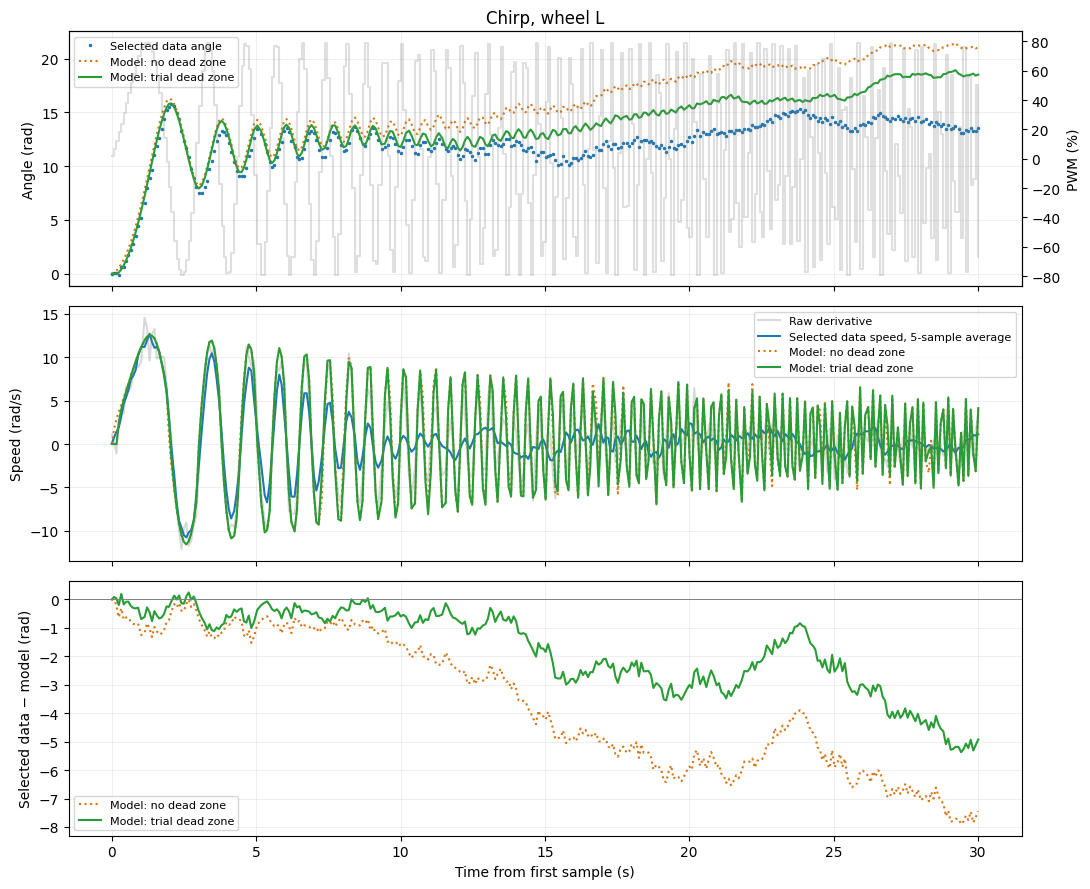

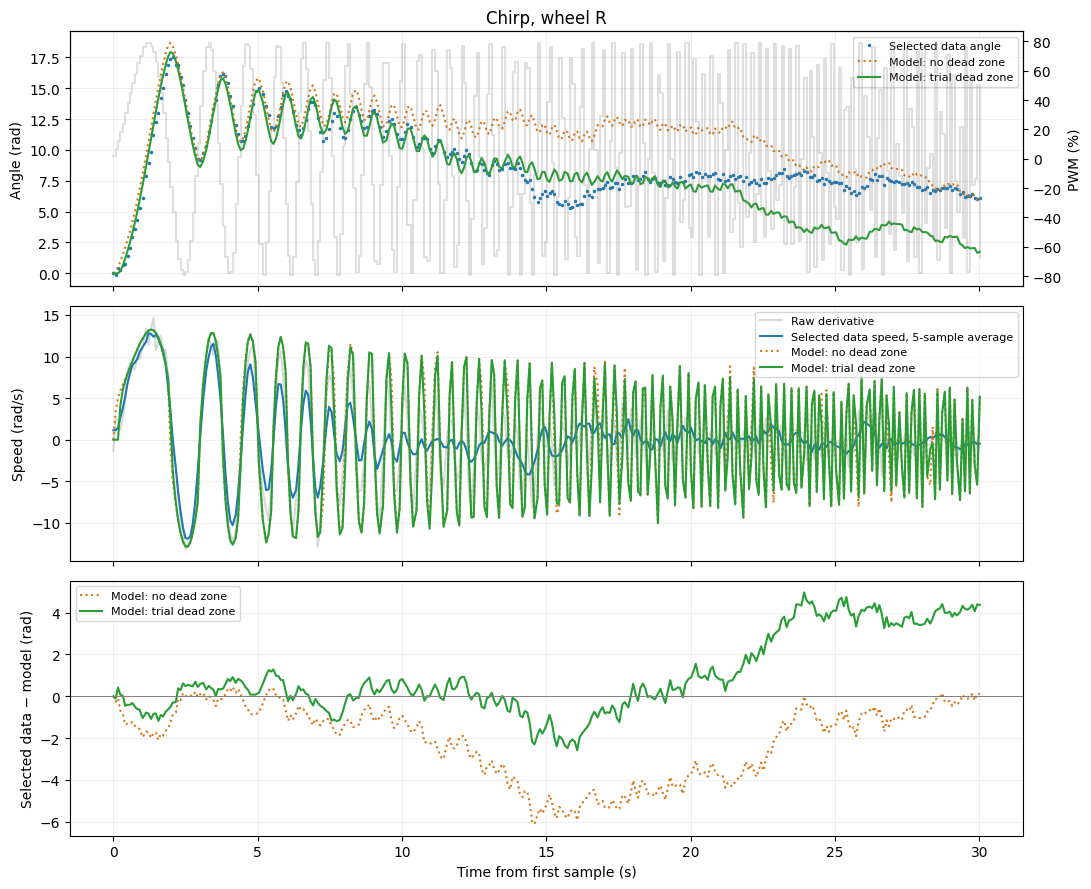

wheel  trial_deadzone  angle_RMSE_rad  angle_fit_percent  filtered_speed_RMSE_rad_s  filtered_speed_fit_percent  largest_angle_error_time_s  signed_largest_error_rad
    L           False           4.364            -68.116                      1.035                      70.579                      29.416                    -7.900
    L            True           2.286             11.935                      1.009                      71.310                      29.416                    -5.369
    R           False           2.784              9.344                      1.584                      58.902                      14.588                    -6.114
    R            True           2.122             30.894                      1.507                      60.904                      23.929                     4.964


In [49]:
sig_all = np.loadtxt(data_path('chirp_wheels_lifted.txt'))
sig = sig_all[sig_all[:, 0] == 3]
t_c = (sig[:, 4] - sig[0, 4]) / 1000
assert np.all(np.diff(t_c) > 0)
pwm_c = sig[:, 1]
U_c = pwm_c / 100 * sig[:, 5]
meas = {'L': np.deg2rad(sig[:, 2] - sig[0, 2]), 'R': np.deg2rad(sig[:, 3] - sig[0, 3])}

def simulate_chirp(wh, dead_zone):
    angle = np.zeros(len(t_c))
    speed = np.zeros(len(t_c))
    for k, dt in enumerate(np.diff(t_c)):
        p = params[wh, 'fwd' if pwm_c[k] > 0 else 'rev']
        target = U_c[k] / p['k_e'] + p['b']
        if pwm_c[k] == 0 or (dead_zone and abs(pwm_c[k]) < p['dz']):
            target = 0.0
        decay = np.exp(-dt / p['T_m'])
        angle[k + 1] = angle[k] + target * dt + (speed[k] - target) * p['T_m'] * (1 - decay)
        speed[k + 1] = target + (speed[k] - target) * decay
    return (angle, speed)

def fit_percent(y, pred):
    den = np.linalg.norm(y - y.mean())
    return 100 * (1 - np.linalg.norm(y - pred) / den) if den > 0 else np.nan
predictions = {}
speed_measured = {}
metrics = []
for wh in ('L', 'R'):
    raw_speed = np.gradient(meas[wh], t_c)
    smoothed = pd.Series(raw_speed).rolling(5, center=True, min_periods=1).mean().to_numpy()
    speed_measured[wh] = smoothed
    fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
    axes[0].plot(t_c, meas[wh], '.', label='Selected data angle', markersize=3)
    axes[1].plot(t_c, raw_speed, color='grey', alpha=0.3, label='Raw derivative')
    axes[1].plot(t_c, smoothed, label='Selected data speed, 5-sample average')
    for dz, style, color in [(False, ':', '#d87515'), (True, '-', '#289c35')]:
        angle, speed = simulate_chirp(wh, dz)
        predictions[wh, dz] = (angle, speed)
        label = 'Model: trial dead zone' if dz else 'Model: no dead zone'
        axes[0].plot(t_c, angle, style, color=color, label=label)
        axes[1].plot(t_c, speed, style, color=color, label=label)
        error = meas[wh] - angle
        axes[2].plot(t_c, error, style, color=color, label=label)
        idx = np.argmax(abs(error))
        filtered_model_speed = pd.Series(speed).rolling(5, center=True, min_periods=1).mean().to_numpy()
        metrics.append([wh, dz, np.sqrt(np.mean(error ** 2)), fit_percent(meas[wh], angle), np.sqrt(np.mean((smoothed - filtered_model_speed) ** 2)), fit_percent(smoothed, filtered_model_speed), t_c[idx], error[idx]])
    ax_pwm = axes[0].twinx()
    ax_pwm.step(t_c, pwm_c, where='post', color='grey', alpha=0.25)
    ax_pwm.set_ylabel('PWM (%)')
    axes[0].set(title=f'Chirp, wheel {wh}', ylabel='Angle (rad)')
    axes[1].set_ylabel('Speed (rad/s)')
    axes[2].set(xlabel='Time from first sample (s)', ylabel='Selected data − model (rad)')
    axes[2].axhline(0, color='grey', linewidth=0.7)
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
metric_table = pd.DataFrame(metrics, columns=['wheel', 'trial_deadzone', 'angle_RMSE_rad', 'angle_fit_percent', 'filtered_speed_RMSE_rad_s', 'filtered_speed_fit_percent', 'largest_angle_error_time_s', 'signed_largest_error_rad'])
print(metric_table.round(3).to_string(index=False))

**Chirp caption:** points/curves marked “recorded” come from the data. Model curves are predictions from the step-based parameters, not another experiment. The table gives angle and smoothed-speed metrics separately, including where angle error is largest. Step fitting alone cannot establish predictive accuracy.

## 5. Chirp amplitude ratio

The source command is a swept sine: frequency increases as `0.1 + (5-0.1)*t/30` Hz. For each usable local period, I estimate speed amplitude divided by estimated voltage amplitude using peak-to-peak ranges. I compare it with `1/(k_e*sqrt(1+(2*pi*f*Tm)**2))` using average directional constants.

This formula describes the linear zero-intercept model. The directional-intercept/dead-zone model is nonlinear and has no single amplitude-independent frequency-response curve. The comparison is therefore approximate. Raw differentiated speed is used here to avoid adding the five-sample smoothing filter's attenuation, but it is noisier. At the high-frequency end there are very few samples per cycle, making amplitude estimates unreliable.


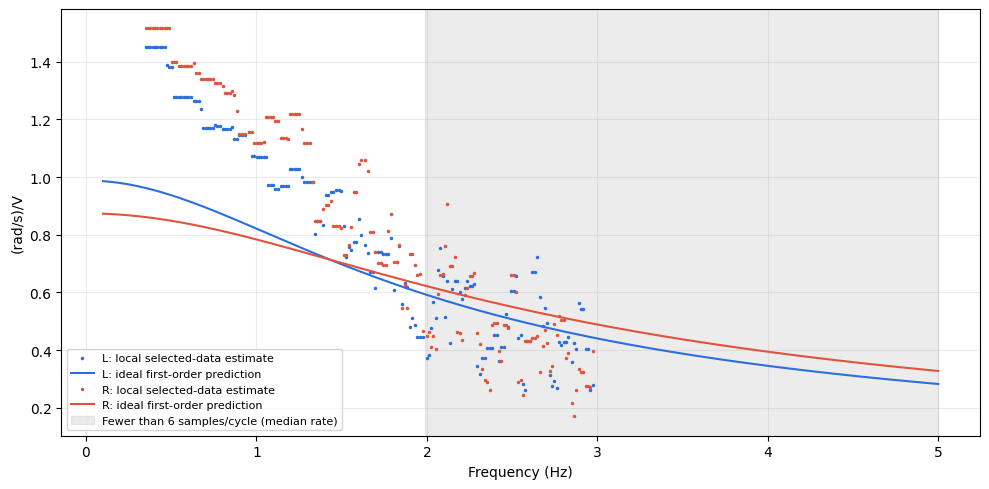

Median sample rate: 11.93 Hz; samples per cycle at 5 Hz: 2.39


In [50]:
f0, f1, T_chirp = (0.1, 5, 30)
f_c = f0 + (f1 - f0) * (sig[:, 4] / 1000) / T_chirp
f_line = np.linspace(f0, f1, 200)
fs = 1 / np.median(np.diff(t_c))
plt.figure(figsize=(10, 5))
for wh in ('L', 'R'):
    velocity = np.gradient(meas[wh], t_c)
    ratio = np.full(len(t_c), np.nan)
    for k, f in enumerate(f_c):
        half = 0.5 / f
        if t_c[k] - half >= t_c[0] and t_c[k] + half <= t_c[-1]:
            win = abs(t_c - t_c[k]) <= half
            if win.sum() >= 4 and np.ptp(U_c[win]) > 0:
                ratio[k] = np.ptp(velocity[win]) / np.ptp(U_c[win])
    ke = np.mean([params[wh, d]['k_e'] for d in ('fwd', 'rev')])
    tm = np.mean([params[wh, d]['T_m'] for d in ('fwd', 'rev')])
    plt.plot(f_c, ratio, '.', color=colors[wh], label=f'{wh}: local selected-data estimate', markersize=3)
    plt.plot(f_line, 1 / (ke * np.sqrt(1 + (2 * np.pi * f_line * tm) ** 2)), color=colors[wh], label=f'{wh}: ideal first-order prediction')
plt.axvspan(fs / 6, f1, color='grey', alpha=0.15, label='Fewer than 6 samples/cycle (median rate)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('(rad/s)/V')
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f'Median sample rate: {fs:.2f} Hz; samples per cycle at 5 Hz: {fs / 5:.2f}')

**Frequency caption:** local amplitude estimates are affected by changing frequency, noise and sparse sampling. The grey region marks limited sampling, not a measured motor cutoff frequency.

## 6. Artifacts, repeatability and load

The initial phase-2 block has only one recorded row after waiting about 3 seconds. It is not a continuous 3-second drift trace. The separate zero-PWM step supplies a short multi-sample stationary record.

The following checks use actual time intervals within each phase/level. Zero-power rows are phase 0; their stored PWM field is a level label, not the command currently applied.


run1, 0 % level: 46 samples over 1.9 s, max |θ|: L 0°, R 0°
run2, 0 % level: 37 samples over 1.9 s, max |θ|: L 0°, R 0°
steps, run 1: Δt median 42 ms, 95th percentile 51 ms, max 72 ms
steps, run 2: Δt median 52 ms, 95th percentile 65 ms, max 93 ms
chirp: Δt median 84 ms, 95th percentile 111 ms, max 135 ms


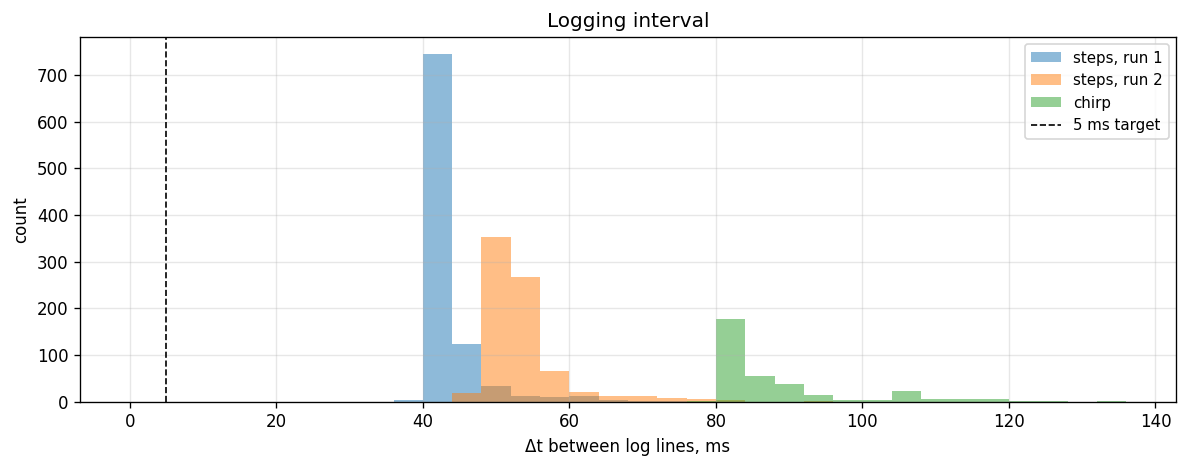

In [51]:
for name in ('run1', 'run2'):
    r0 = next((r for r in all_runs[name] if r['power'] == 0))
    print(f"{name}, 0 % level: {len(r0['time'])} samples over {r0['time'][-1] - r0['time'][0]:.1f} s, max |θ|: L {np.degrees(np.abs(r0['L']).max()):.0f}°, R {np.degrees(np.abs(r0['R']).max()):.0f}°")
dts = {'steps, run 1': np.concatenate([np.diff(r['time']) for r in all_runs['run1']]), 'steps, run 2': np.concatenate([np.diff(r['time']) for r in all_runs['run2']]), 'chirp': np.diff(t_c)}
plt.figure(figsize=(10, 4), dpi=120)
for name, dt in dts.items():
    dt_ms = 1000 * dt
    print(f'{name}: Δt median {np.median(dt_ms):.0f} ms, 95th percentile {np.percentile(dt_ms, 95):.0f} ms, max {dt_ms.max():.0f} ms')
    plt.hist(dt_ms, bins=np.arange(0, 140, 4), alpha=0.5, label=name)
plt.axvline(5, color='k', ls='--', lw=1, label='5 ms target')
plt.xlabel('Δt between log lines, ms')
plt.ylabel('count')
plt.title('Logging interval')
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

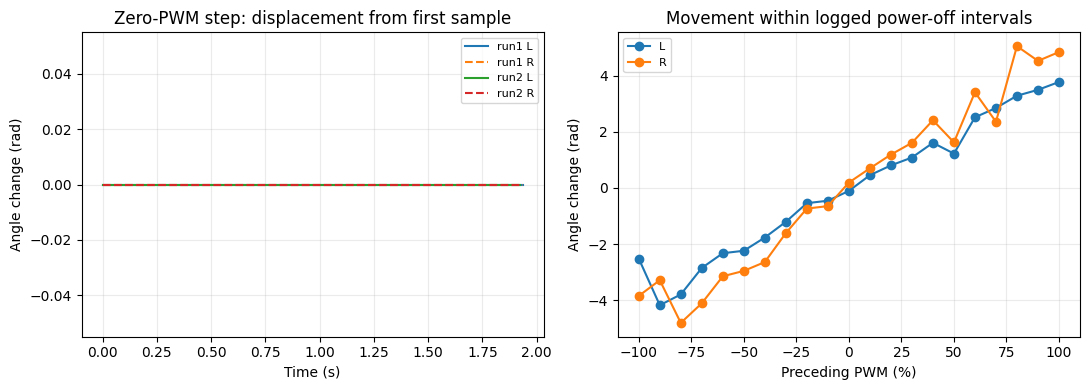

Absolute off-interval movement, min/max rad: 0.017453292519943295 5.672320068981571


In [52]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for name in ('run1', 'run2'):
    z = next((r for r in all_runs[name] if r['power'] == 0))
    for wh, style in [('L', '-'), ('R', '--')]:
        axs[0].plot(z['time'], z[wh], style, label=f'{name} {wh}')
coast_rows = []
for name in ('run1', 'run2'):
    a = raw[name]
    for power in np.unique(a[:, 1]):
        s = a[(a[:, 0] == 0) & (a[:, 1] == power)]
        if len(s) < 2:
            continue
        for wh, col in [('L', 2), ('R', 3)]:
            distance = np.deg2rad(s[-1, col] - s[0, col])
            coast_rows.append([name, power, wh, distance])
coast = pd.DataFrame(coast_rows, columns=['run', 'preceding_PWM', 'wheel', 'off_interval_angle_rad'])
for wh in ('L', 'R'):
    d = coast[(coast.run == 'run1') & (coast.wheel == wh)]
    axs[1].plot(d.preceding_PWM, d.off_interval_angle_rad, 'o-', label=wh)
axs[0].set(title='Zero-PWM step: displacement from first sample', xlabel='Time (s)', ylabel='Angle change (rad)')
axs[1].set(title='Movement within logged power-off intervals', xlabel='Preceding PWM (%)', ylabel='Angle change (rad)')
for ax in axs:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Absolute off-interval movement, min/max rad:', float(abs(coast.off_interval_angle_rad).min()), float(abs(coast.off_interval_angle_rad).max()))

**Artifact captions:** the zero-PWM traces test change during the observed interval only. Power-off displacement is measured from the first logged off sample to the last; it excludes any movement before that first off sample. A reversal delay does not by itself identify gear backlash.

wheel L: speed per volt, run 2 vs run 1: -4.1 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.106 s, run 2 0.096 s
wheel R: speed per volt, run 2 vs run 1: -1.7 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.079 s, run 2 0.073 s
lifted (run 2) → floor:
  PWM  -50, wheel L: ω_ss  -8.28 →  -6.45 rad/s (-22.1 %), T_m 0.151 → 0.210 s
  PWM  -50, wheel R: ω_ss  -9.72 →  -6.94 rad/s (-28.6 %), T_m 0.140 → 0.233 s
  PWM  +50, wheel L: ω_ss   8.54 →   6.78 rad/s (-20.6 %), T_m 0.169 → 0.266 s
  PWM  +50, wheel R: ω_ss   9.89 →   7.33 rad/s (-25.8 %), T_m 0.164 → 0.199 s


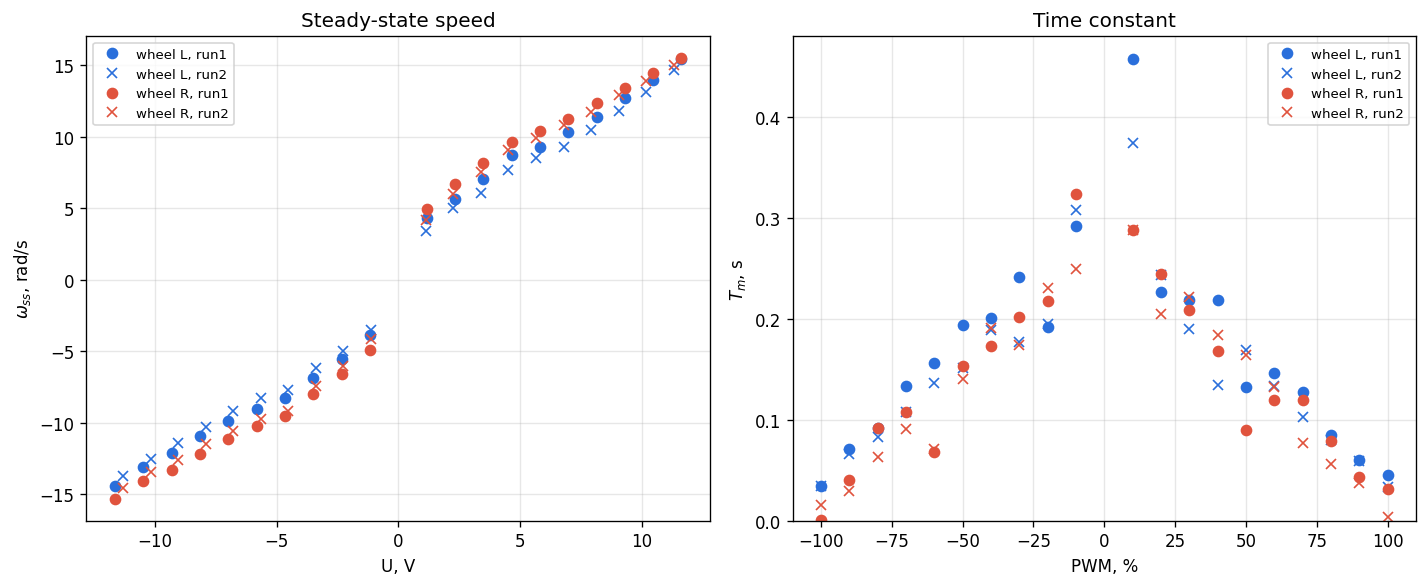

In [53]:
def fit_all(runs):
    res = {wh: np.full((len(runs), 2), np.nan) for wh in ('L', 'R')}
    for wh in ('L', 'R'):
        for i, r in enumerate(runs):
            if abs(r[wh][-1]) >= 1:
                res[wh][i] = fit_run(r['time'], r[wh])[0]
    return res
fits = {name: fit_all(rs) for name, rs in all_runs.items()}
lv = {name: {'pct': np.array([r['power'] for r in rs]), 'U': np.array([r['U'] for r in rs])} for name, rs in all_runs.items()}
assert np.array_equal(lv['run1']['pct'], lv['run2']['pct'])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
hi = np.abs(lv['run1']['pct']) >= 50
for wh in ('L', 'R'):
    for name, mk in (('run1', 'o'), ('run2', 'x')):
        ax1.plot(lv[name]['U'], fits[name][wh][:, 0], mk, color=colors[wh], label=f'wheel {wh}, {name}')
        ax2.plot(lv[name]['pct'], fits[name][wh][:, 1], mk, color=colors[wh], label=f'wheel {wh}, {name}')
    g1 = fits['run1'][wh][hi, 0] / lv['run1']['U'][hi]
    g2 = fits['run2'][wh][hi, 0] / lv['run2']['U'][hi]
    print(f"wheel {wh}: speed per volt, run 2 vs run 1: {100 * np.mean(g2 / g1 - 1):+.1f} % (mean over |PWM| ≥ 50 %); T_m mean: run 1 {np.mean(fits['run1'][wh][hi, 1]):.3f} s, run 2 {np.mean(fits['run2'][wh][hi, 1]):.3f} s")
ax1.set_xlabel('U, V')
ax1.set_ylabel('$\\omega_{ss}$, rad/s')
ax1.set_title('Steady-state speed')
ax2.set_xlabel('PWM, %')
ax2.set_ylabel('$T_m$, s')
ax2.set_title('Time constant')
ax2.set_ylim(bottom=0)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
print('lifted (run 2) → floor:')
for p in (-50, 50):
    i2, i_f = (list(lv['run2']['pct']).index(p), list(lv['floor']['pct']).index(p))
    for wh in ('L', 'R'):
        (w2, T2), (wf, Tf) = (fits['run2'][wh][i2], fits['floor'][wh][i_f])
        print(f'  PWM {p:+4d}, wheel {wh}: ω_ss {w2:6.2f} → {wf:6.2f} rad/s ({100 * (wf / w2 - 1):+.1f} %), T_m {T2:.3f} → {Tf:.3f} s')
plt.show()

**Repeatability/load caption:** step parameters are fitted again for the repeat and loaded recordings. Speed-per-volt comparison partly accounts for different battery levels, but does not remove all friction, load or timing differences. The loaded/unloaded labels come from the supplied notebook. These observations should not be extended to other robots without measurement.

In [54]:
battery_rows = []
for name, a in raw.items():
    battery_rows.append([name, a[0, 5], a[-1, 5], a[:, 5].min(), a[:, 5].max(), 100 * (a[-1, 5] - a[0, 5]) / a[0, 5]])
battery_table = pd.DataFrame(battery_rows, columns=['run', 'first_logged_V', 'last_logged_V', 'min_V', 'max_V', 'first_to_last_percent'])
print(battery_table.round(4).to_string(index=False))
print('Directional high-range slope difference relative to reverse:')
for wh in ('L', 'R'):
    print(wh, round(100 * (params[wh, 'fwd']['slope'] / params[wh, 'rev']['slope'] - 1), 2), '%')

  run  first_logged_V  last_logged_V   min_V   max_V  first_to_last_percent
 run1         11.6749        11.6360 11.6360 11.6749                -0.3330
 run2         11.3120        11.3120 11.2861 11.3250                 0.0000
floor         11.2861        11.2861 11.2861 11.2991                 0.0000
chirp         11.6360        11.6230 11.5323 11.6360                -0.1114
Directional high-range slope difference relative to reverse:
L 14.63 %
R 1.84 %


7. ***Discussion***

**Model quality.** The model follows part of the motion, but misses some changes. Added encoder noise also affects the results.

**Forward and backward**. The two directions give different results. Separate settings might help, but we need repeated tests to be sure.

**Artifacts and odometry**. The restored zero-PWM readings stay flat. Noise elsewhere and uneven timing affect speed calculations and position estimates.

**Chirp signal**. The chirp shows how the motor handles faster changes and reversals. Near 5 Hz, there are too few samples for a reliable estimate.